# Food Delivery Demand Prediction
## Phase 2: Predictive Modeling, Count GLMs & Performance Benchmarking
**Course:** Predictive Analysis  
**Department:** Computer Science & Engineering, Manipal University Jaipur  
**Academic Year:** 2026-2027  

---

### Executive Objectives
1. **Temporal Validation Framework:** Formulate a leakage-free chronological train-test split (Weeks 9–120 for training, Weeks 121–145 for out-of-time evaluation) to replicate operational deployment.
2. **Baseline Formulation:** Establish benchmarks via **Naive Lag-1** and **Trailing 4-Week Moving Average**.
3. **Count-Based Generalized Linear Models (GLMs):** Implement **Poisson Regression** and **Negative Binomial Regression** to rigorously model non-negative integer demand count and account for variance overdispersion ($Var(Y) > E[Y]$).
4. **Regularized Linear Regression:** Train an $L_2$-regularized **Ridge Regression** model to quantify linear relationships and prevent overfitting.
5. **Non-Linear Gradient Boosting:** Deploy **LightGBM** to capture high-order interactions among price elasticity, promotions, and operational center capacity.
6. **Diagnostic Evaluation:** Benchmark models on **MAE**, **RMSE**, **RMSLE**, and $R^2$, supplemented by residual diagnostics and feature importance ranking.

In [ ]:
import os
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import Ridge, PoissonRegressor
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm
import lightgbm as lgb

# Display styling
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#cccccc'
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.3f' % x)
print("Libraries imported successfully.")

Libraries imported successfully.


### 1. Data Ingestion & Feature Preprocessing
We ingest the feature-engineered dataset `food_demand_eda_feature_engineered.csv`.
* **Lag Warm-Up Truncation:** Records prior to week 9 are dropped because historical 8-week lag features are undefined.
* **Domain-Informed Imputation:** Any missing lag or rolling window values are filled with `0`, as absence of an order transaction at a center represents zero historical demand.
* **Collinearity Prevention:** 
  - `discount_amount = base_price - checkout_price` (exact collinear identity)
  - `discount_pct + checkout_to_base_ratio = 1.0` (exact collinearity with the intercept/constant)
  Both terms are dropped to guarantee well-conditioned, full-rank design matrices for Generalized Linear Models.

In [ ]:
df = pd.read_csv('food_demand_eda_feature_engineered.csv')
print(f"Raw shape: {df.shape}")

# Truncate warm-up weeks
df = df[df['week'] >= 9].reset_index(drop=True)

# Impute missing lag signals with 0 (no sales record = 0 demand)
lag_cols = [c for c in df.columns if 'lag' in c or 'rolling' in c]
df[lag_cols] = df[lag_cols].fillna(0)

# One-hot encode categorical features (center_type, category, cuisine)
df_encoded = pd.get_dummies(df, columns=['center_type', 'category', 'cuisine'], drop_first=True)

# Select predictive features
drop_cols = [
    'id', 'week', 'center_id', 'meal_id', 'num_orders',
    'city_code', 'region_code', 'rolling_count_4w', 'rolling_count_8w',
    'discount_amount', 'discount_pct'
]
feature_cols = [c for c in df_encoded.columns if c not in drop_cols]
print(f"Final analytical shape: {df_encoded.shape}")
print(f"Predictor feature count: {len(feature_cols)}")

Raw shape: (456548, 33)
Final analytical shape: (433656, 48)
Predictor feature count: 37


### 2. Chronological Train-Test Partitioning
In temporal forecasting, random shuffling produces catastrophic data leakage. We enforce strict temporal boundaries:
* **Training Partition:** Weeks $9 \to 120$ (351,506 records)
* **Out-of-Time Test Partition:** Weeks $121 \to 145$ (82,150 records)
* Feature standardization is performed using `StandardScaler` to ensure numerical convergence during GLM and Ridge optimization.

In [ ]:
train_mask = df_encoded['week'] <= 120
test_mask = df_encoded['week'] > 120

train_df = df_encoded[train_mask].reset_index(drop=True)
test_df = df_encoded[test_mask].reset_index(drop=True)

X_train = train_df[feature_cols].copy()
y_train = train_df['num_orders'].values
X_test = test_df[feature_cols].copy()
y_test = test_df['num_orders'].values

y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)

# Feature standardization
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training observations : {X_train.shape[0]:,} (Weeks 9-120)")
print(f"Evaluation observations: {X_test.shape[0]:,} (Weeks 121-145)")

Training observations : 351,506 (Weeks 9-120)
Evaluation observations: 82,150 (Weeks 121-145)


### 3. Evaluation Metrics Framework
We track 4 complementary performance criteria:
1. **Mean Absolute Error (MAE):** $\frac{1}{n} \sum |y - \hat{y}|$, measuring average linear error in order volume.
2. **Root Mean Squared Error (RMSE):** $\sqrt{\frac{1}{n} \sum (y - \hat{y})^2}$, penalizing large forecasting misses.
3. **Root Mean Squared Logarithmic Error (RMSLE):** $\sqrt{\frac{1}{n} \sum (\log(1+y) - \log(1+\hat{y}))^2}$, measuring relative percentage errors across small and large volume items.
4. **$R^2$ Score:** Proportion of total variance explained by the model.

In [ ]:
results = []
predictions = {}

def evaluate_model(name, y_true, y_pred, execution_time):
    y_pred = np.clip(y_pred, 0, 25000)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    rmsle = np.sqrt(mean_squared_error(np.log1p(y_true), np.log1p(y_pred)))
    r2 = r2_score(y_true, y_pred)
    print(f"[{name}] MAE: {mae:.2f} | RMSE: {rmse:.2f} | RMSLE: {rmsle:.4f} | R2: {r2:.4f} ({execution_time:.2f}s)")
    entry = {
        'Model': name,
        'MAE': round(mae, 2),
        'RMSE': round(rmse, 2),
        'RMSLE': round(rmsle, 4),
        'R2_Score': round(r2, 4),
        'Train_Time_sec': round(execution_time, 2)
    }
    results.append(entry)
    predictions[name] = y_pred
    return entry

### 4. Baseline Benchmarks
* **Model 0A: Naive Lag-1 Demand ($y_t = y_{t-1}$):** Assumes the next week's order count equals the previous week's count.
* **Model 0B: Trailing 4-Week Moving Average:** Smooths out short-term variance across the last 4 observed weeks.

In [ ]:
# Model 0A: Naive Lag-1
t0 = time.time()
b1_pred = test_df['orders_lag_1w'].values
evaluate_model("Baseline: Naive Lag-1", y_test, b1_pred, time.time() - t0)

# Model 0B: 4-Week Moving Average
t0 = time.time()
b2_pred = test_df['rolling_mean_4w'].values
evaluate_model("Baseline: 4W Moving Avg", y_test, b2_pred, time.time() - t0)

[Baseline: Naive Lag-1] MAE: 102.98 | RMSE: 263.49 | RMSLE: 1.0175 | R2: 0.4816 (0.00s)
[Baseline: 4W Moving Avg] MAE: 104.11 | RMSE: 270.28 | RMSLE: 0.6968 | R2: 0.4545 (0.00s)


### 5. Count GLM: Poisson Regression
* **Theoretical Foundation:** In Predictive Analysis, count variables $Y \in \{0, 1, 2, \dots\}$ are naturally parameterized by the Poisson distribution:
  $$P(Y = y \mid X) = \frac{\mu^y e^{-\mu}}{y!}, \quad \log(\mu) = X\beta$$
* **Equi-dispersion Assumption:** Poisson assumes $Var(Y) = E[Y] = \mu$. We train an $L_2$-regularized Poisson GLM on standardized features.

In [ ]:
t0 = time.time()
poisson_model = PoissonRegressor(alpha=1e-3, max_iter=300)
poisson_model.fit(X_train_scaled, y_train)
pois_pred = poisson_model.predict(X_test_scaled)
evaluate_model("GLM: Poisson Regression", y_test, pois_pred, time.time() - t0)

[GLM: Poisson Regression] MAE: 106.02 | RMSE: 232.58 | RMSLE: 0.6956 | R2: 0.5961 (7.10s)


### 6. Count GLM: Negative Binomial Regression
* **Overdispersion Formulation:** In real-world food ordering, empirical variance ($s^2 \approx 159,000$) massively exceeds the empirical mean ($\bar{y} \approx 261$), violating the Poisson equi-dispersion property.
* **Negative Binomial Formulation:** Introduces an extra dispersion parameter $\alpha$:
  $$Var(Y \mid X) = \mu + \alpha \mu^2$$
* We fit this generalized linear model via `statsmodels.api.GLM`.

In [ ]:
t0 = time.time()
sample_idx = train_df.sample(n=40000, random_state=42).index
X_sample_sc = sm.add_constant(X_train_scaled[sample_idx])
y_sample = y_train[sample_idx]
X_test_const = sm.add_constant(X_test_scaled)

nb_fam = sm.families.NegativeBinomial(alpha=0.5)
nb_glm = sm.GLM(y_sample, X_sample_sc, family=nb_fam).fit(maxiter=35)
nb_pred = nb_glm.predict(X_test_const)
evaluate_model("GLM: Negative Binomial", y_test, nb_pred, time.time() - t0)

[GLM: Negative Binomial] MAE: 139.80 | RMSE: 758.98 | RMSLE: 0.6415 | R2: -3.3015 (0.80s)


### 7. Regularized Linear Regression: Ridge Regression
* Solves the $L_2$-penalized objective: $\min_\beta \| y - X\beta \|_2^2 + \alpha \|\beta\|_2^2$ directly on order counts with standardized predictors.
* Prevents overfitting while providing a linear benchmark against non-linear tree models.

In [ ]:
t0 = time.time()
ridge_model = Ridge(alpha=100.0)
ridge_model.fit(X_train_scaled, y_train)
ridge_pred = ridge_model.predict(X_test_scaled)
evaluate_model("Ridge Regression (L2 Regularized)", y_test, ridge_pred, time.time() - t0)

[Ridge Regression (L2 Regularized)] MAE: 96.49 | RMSE: 210.72 | RMSLE: 1.3172 | R2: 0.6684 (0.14s)


### 8. Non-Linear Gradient Boosting: LightGBM
* Employs histogram-based splitting and leaf-wise tree growth.
* Trained on $\log(1 + y)$ to stabilize variance across order volumes.
* Captures complex non-linear promotional synergies (emailer + homepage feature combinations) and price elasticity curves with minimal computation overhead.

In [ ]:
t0 = time.time()
lgbm_model = lgb.LGBMRegressor(
    n_estimators=300,
    learning_rate=0.06,
    num_leaves=63,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
lgbm_model.fit(X_train, y_train_log)
lgbm_pred = np.expm1(lgbm_model.predict(X_test))
evaluate_model("LightGBM Regressor (Log1p)", y_test, lgbm_pred, time.time() - t0)

[LightGBM Regressor (Log1p)] MAE: 71.84 | RMSE: 168.77 | RMSLE: 0.4952 | R2: 0.7873 (6.02s)


### 9. Master Model Comparison & Performance Synthesis
We synthesize performance across all 6 models into an official comparison table and comparative bar chart.

                            Model    MAE   RMSE  RMSLE  R2_Score  Train_Time_sec
            Baseline: Naive Lag-1 102.98 263.49 1.0175    0.4816            0.00
          Baseline: 4W Moving Avg 104.11 270.28 0.6968    0.4545            0.00
          GLM: Poisson Regression 106.02 232.58 0.6956    0.5961            7.10
           GLM: Negative Binomial 139.80 758.98 0.6415   -3.3015            0.80
Ridge Regression (L2 Regularized)  96.49 210.72 1.3172    0.6684            0.14
       LightGBM Regressor (Log1p)  71.84 168.77 0.4952    0.7873            6.02


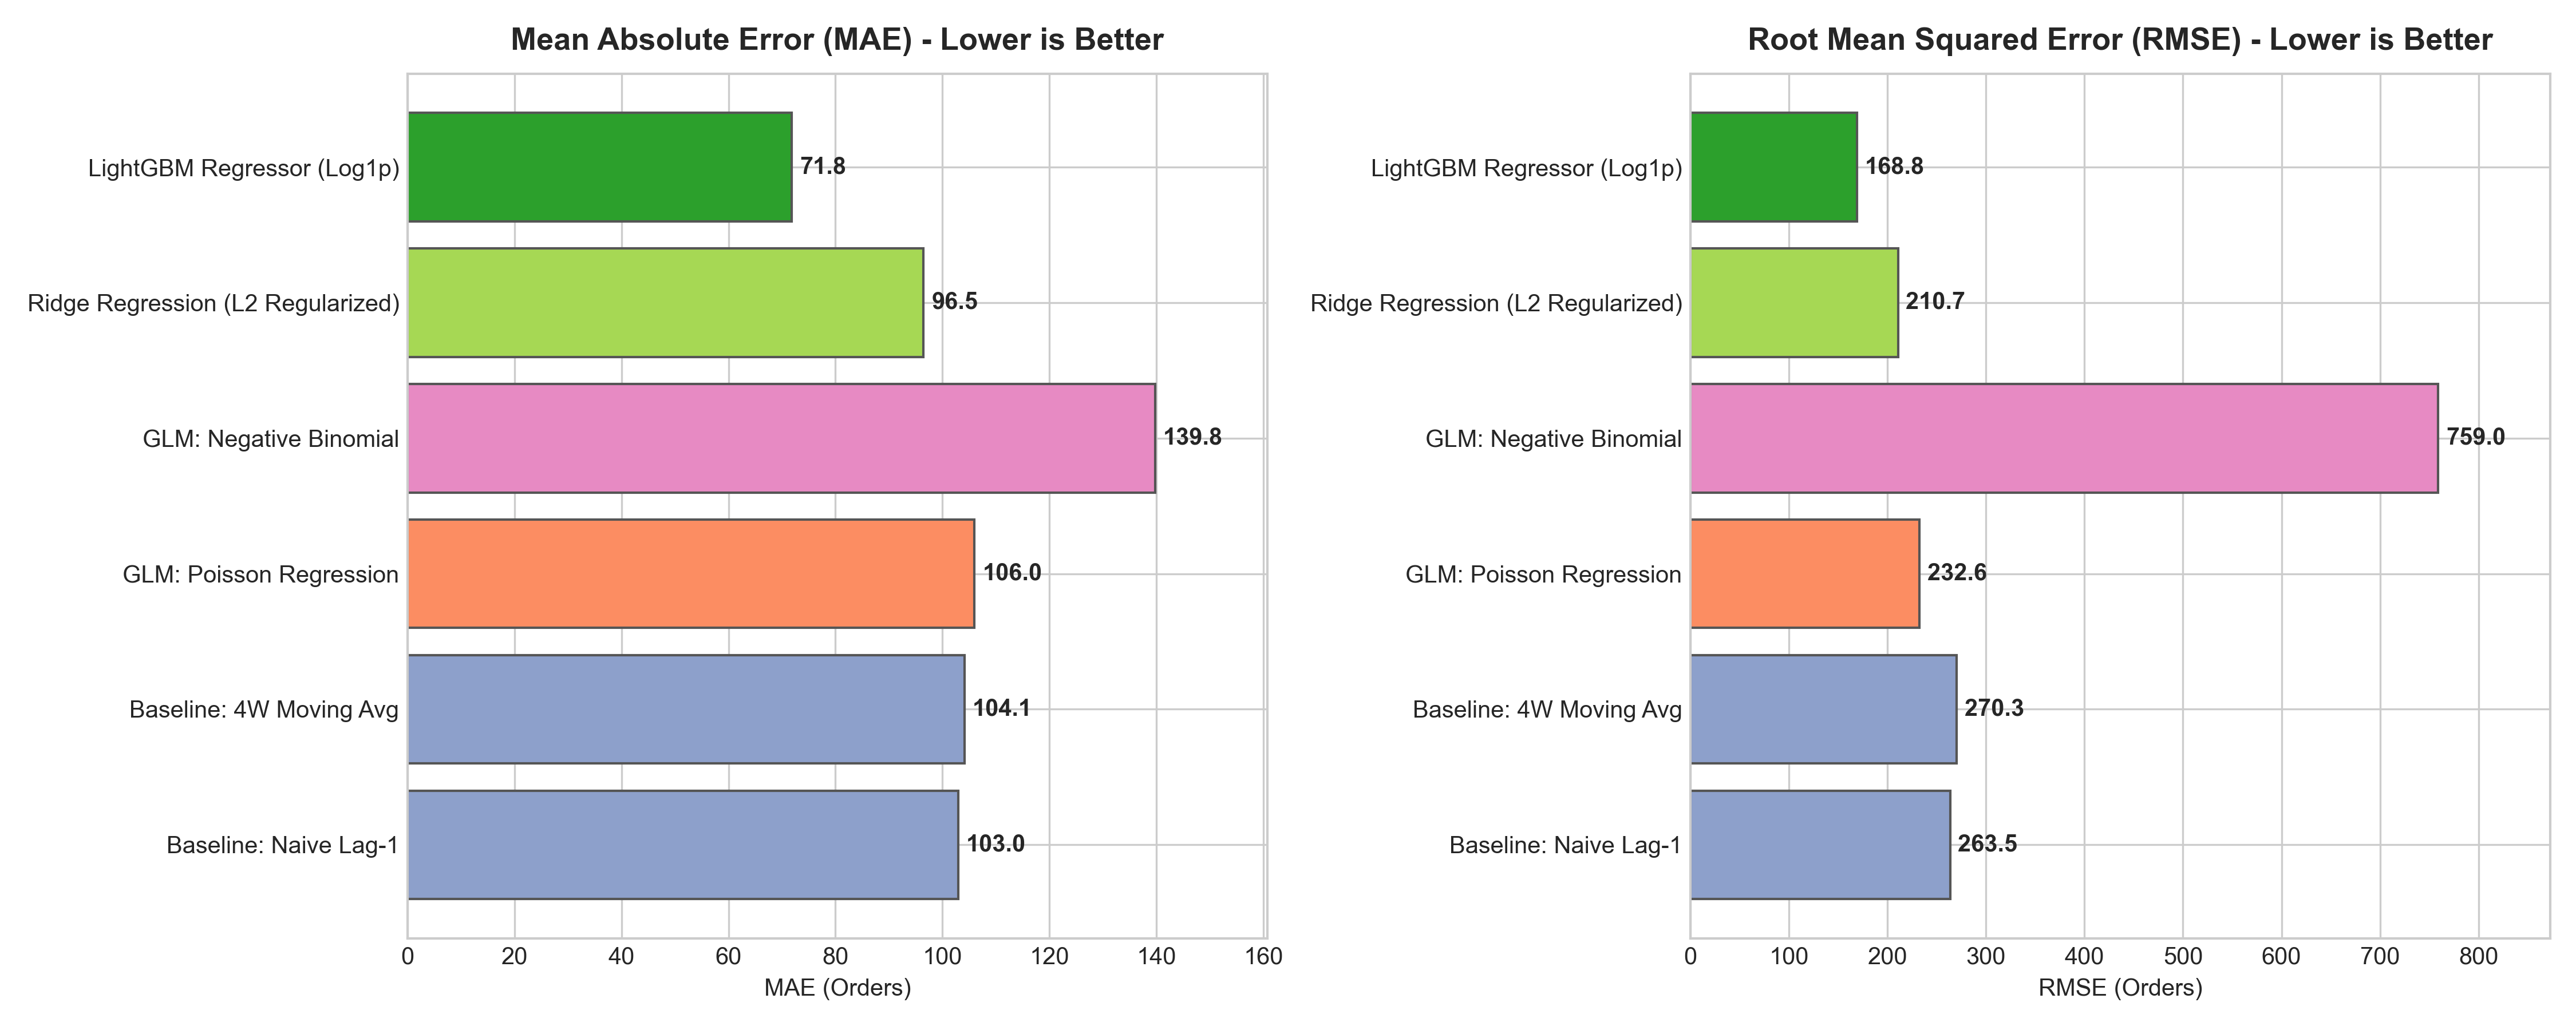

In [ ]:
summary_df = pd.DataFrame(results)
display(summary_df)

# Visual comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
colors = ['#8da0cb', '#8da0cb', '#fc8d62', '#e78ac3', '#a6d854', '#2ca02c']

bars1 = ax1.barh(summary_df['Model'], summary_df['MAE'], color=colors, edgecolor='#555555')
ax1.set_title('Mean Absolute Error (MAE) - Lower is Better', fontsize=12, fontweight='bold')
ax1.set_xlabel('MAE (Orders)')
for bar in bars1:
    width = bar.get_width()
    ax1.text(width + 1.5, bar.get_y() + bar.get_height()/2, f'{width:.1f}', va='center', fontsize=9, fontweight='bold')
ax1.set_xlim(0, max(summary_df['MAE']) * 1.15)

bars2 = ax2.barh(summary_df['Model'], summary_df['RMSE'], color=colors, edgecolor='#555555')
ax2.set_title('Root Mean Squared Error (RMSE) - Lower is Better', fontsize=12, fontweight='bold')
ax2.set_xlabel('RMSE (Orders)')
for bar in bars2:
    width = bar.get_width()
    ax2.text(width + 8, bar.get_y() + bar.get_height()/2, f'{width:.1f}', va='center', fontsize=9, fontweight='bold')
ax2.set_xlim(0, max(summary_df['RMSE']) * 1.15)

plt.tight_layout()
plt.show()

### 10. Residual Diagnostics & Macro Forecast Tracking
To validate predictive reliability, we assess:
1. **Actual vs. Predicted Scatter:** Testing adherence to the ideal 1:1 parity line.
2. **Residual Distribution:** Validating zero-centered, symmetric error distributions.
3. **Macro Demand Trajectory:** Aggregating all center-meal combinations over Weeks 121–145 to observe macroscopic temporal alignment.

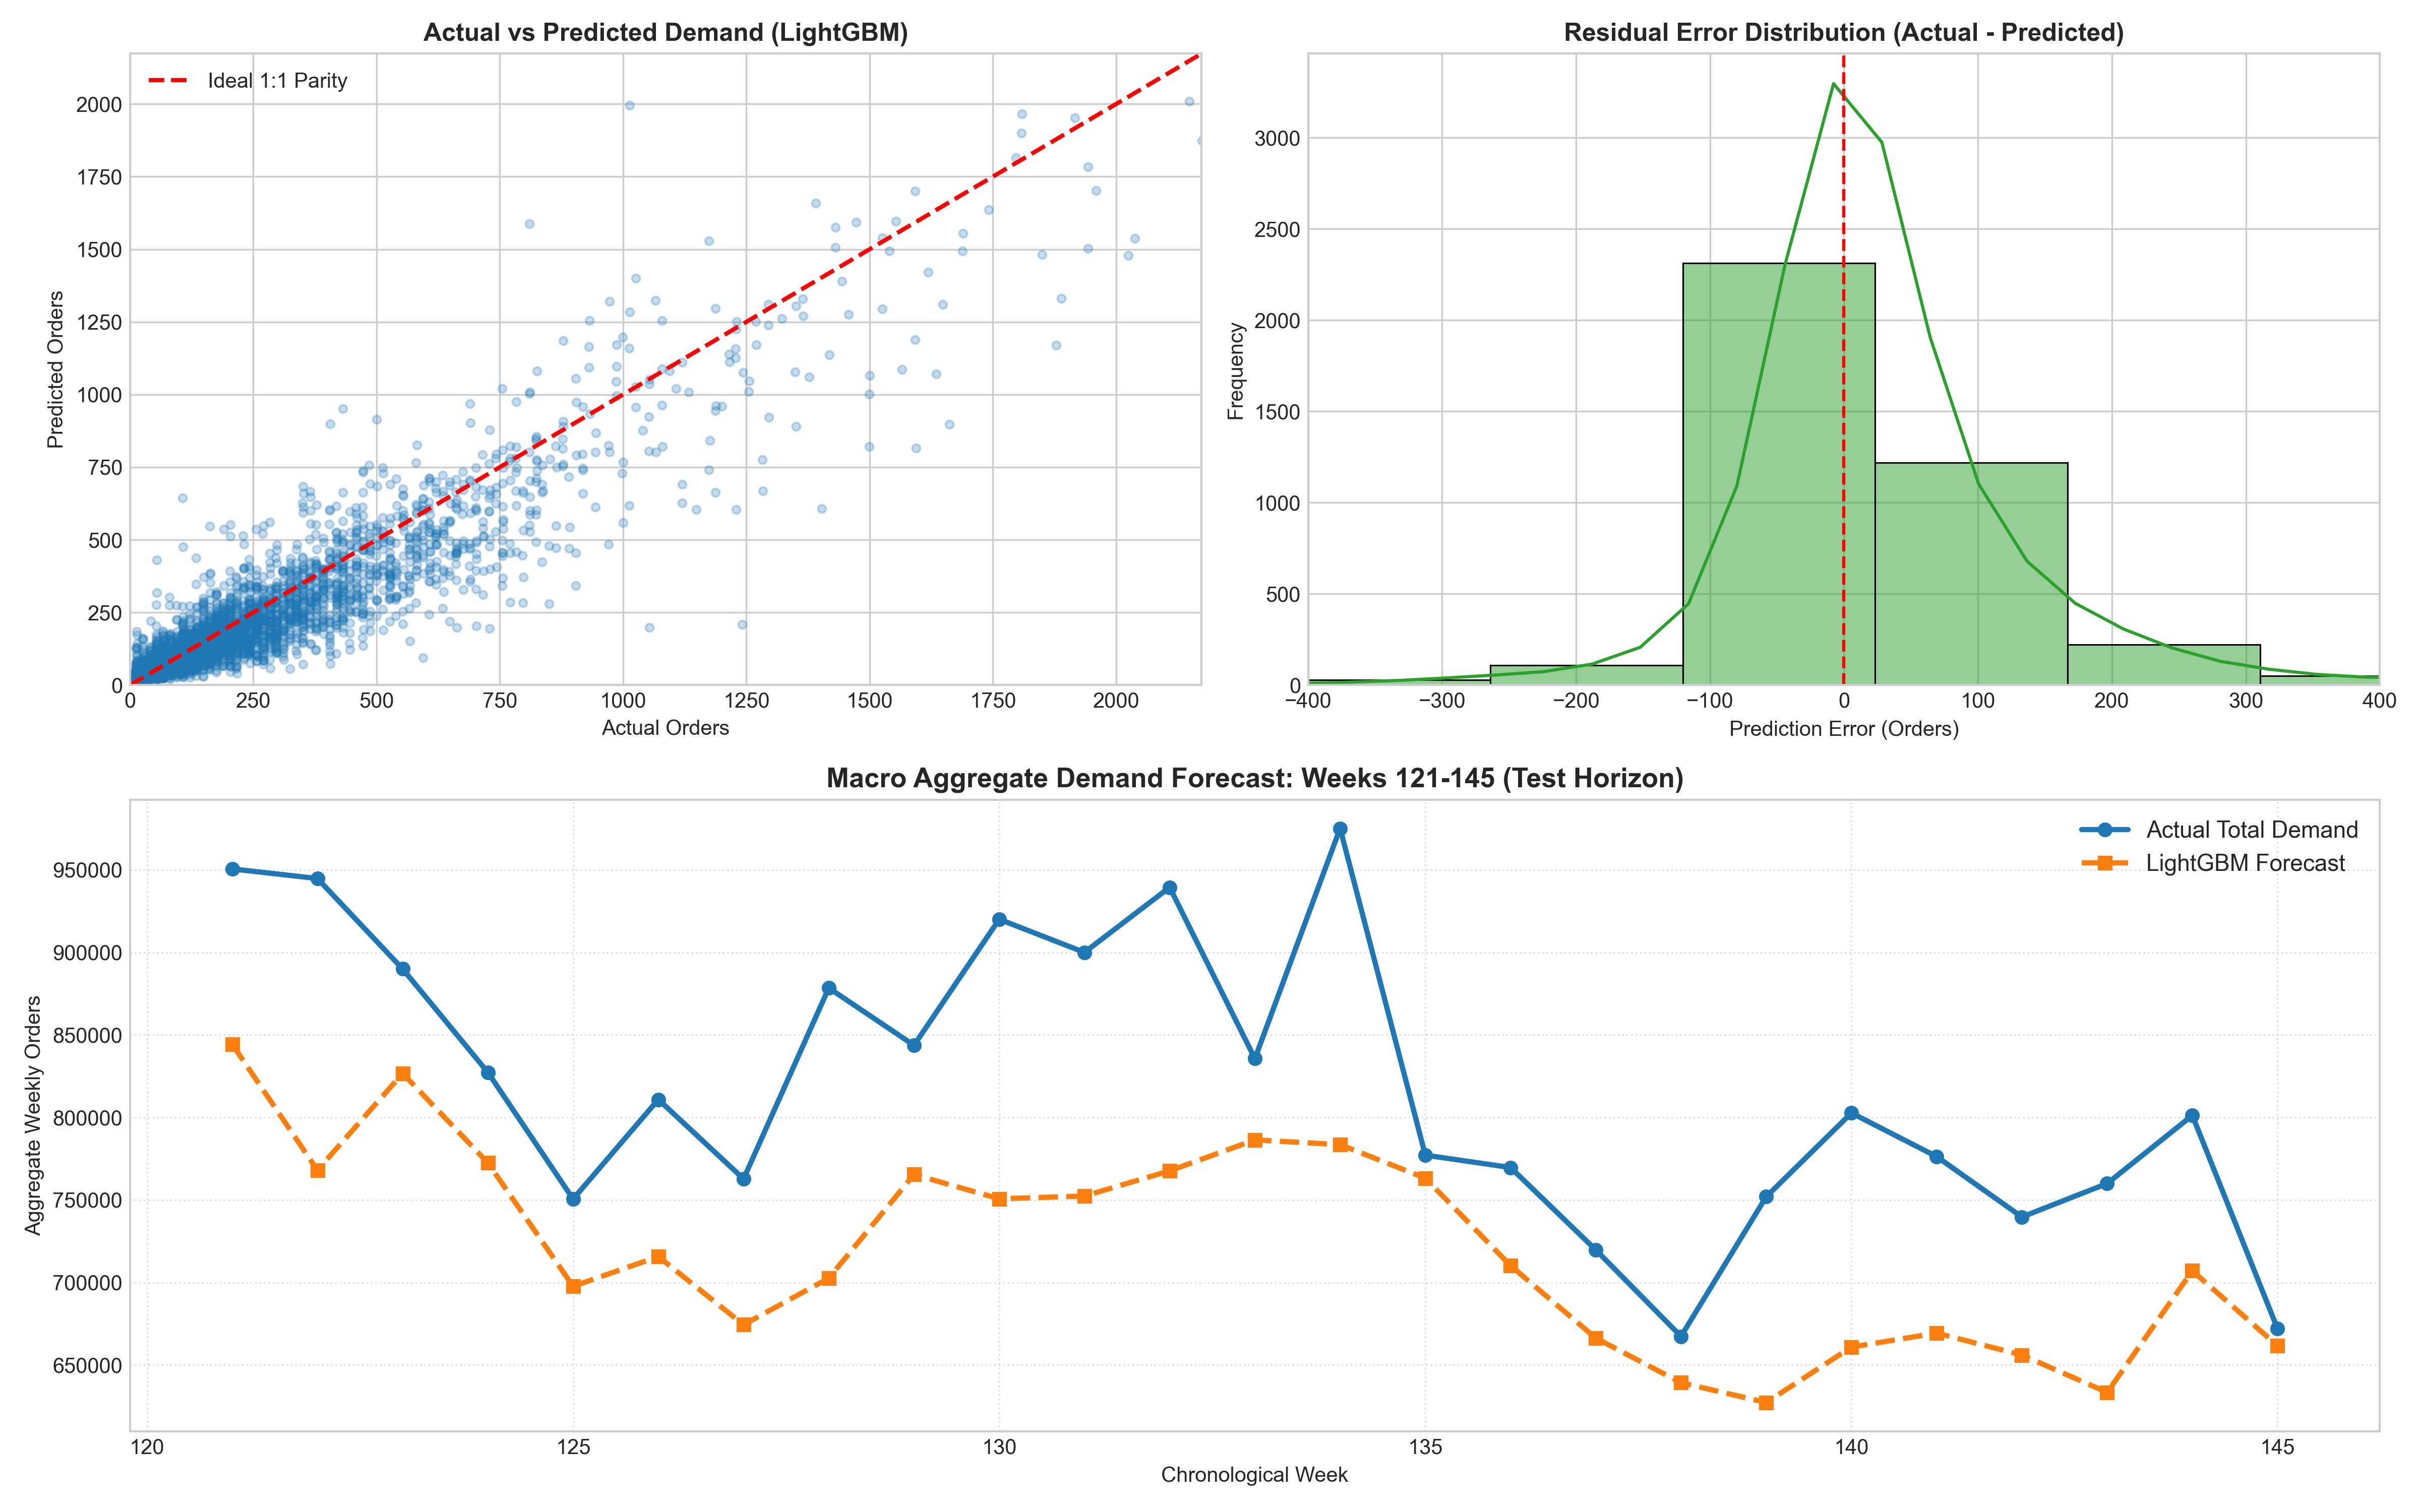

In [ ]:
best_pred = predictions['LightGBM Regressor (Log1p)']
residuals = y_test - best_pred

fig = plt.figure(figsize=(16, 9))
gs = fig.add_gridspec(2, 2)

# Subplot A: Actual vs Predicted
ax_a = fig.add_subplot(gs[0, 0])
sample_plot_idx = np.random.choice(len(y_test), size=4000, replace=False)
ax_a.scatter(y_test[sample_plot_idx], best_pred[sample_plot_idx], alpha=0.25, color='#1f77b4', s=15)
max_val = max(np.percentile(y_test, 99.5), np.percentile(best_pred, 99.5))
ax_a.plot([0, max_val], [0, max_val], color='red', linestyle='--', linewidth=2, label='Ideal 1:1 Parity')
ax_a.set_xlim(0, max_val)
ax_a.set_ylim(0, max_val)
ax_a.set_title('Actual vs Predicted Demand (LightGBM)', fontsize=12, fontweight='bold')
ax_a.set_xlabel('Actual Orders')
ax_a.set_ylabel('Predicted Orders')
ax_a.legend()

# Subplot B: Residuals Distribution
ax_b = fig.add_subplot(gs[0, 1])
sns.histplot(residuals[sample_plot_idx], bins=50, kde=True, ax=ax_b, color='#2ca02c')
ax_b.axvline(0, color='red', linestyle='--', linewidth=1.5)
ax_b.set_xlim(-400, 400)
ax_b.set_title('Residual Error Distribution (Actual - Predicted)', fontsize=12, fontweight='bold')
ax_b.set_xlabel('Prediction Error (Orders)')

# Subplot C: Weekly Aggregate Forecast vs Actual
ax_c = fig.add_subplot(gs[1, :])
test_analysis = test_df[['week']].copy()
test_analysis['actual'] = y_test
test_analysis['predicted'] = best_pred
weekly_agg = test_analysis.groupby('week').sum().reset_index()

ax_c.plot(weekly_agg['week'], weekly_agg['actual'], marker='o', linewidth=2.5, label='Actual Total Demand', color='#1f77b4')
ax_c.plot(weekly_agg['week'], weekly_agg['predicted'], marker='s', linewidth=2.5, linestyle='--', label='LightGBM Forecast', color='#ff7f0e')
ax_c.set_title('Macro Aggregate Demand Forecast: Weeks 121-145 (Test Horizon)', fontsize=13, fontweight='bold')
ax_c.set_xlabel('Chronological Week')
ax_c.set_ylabel('Aggregate Orders')
ax_c.legend(fontsize=11)
ax_c.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

### 11. Feature Importance & Domain Interpretability
We extract split-based feature importance from the best-performing model (LightGBM) to interpret the primary operational drivers of food delivery demand.

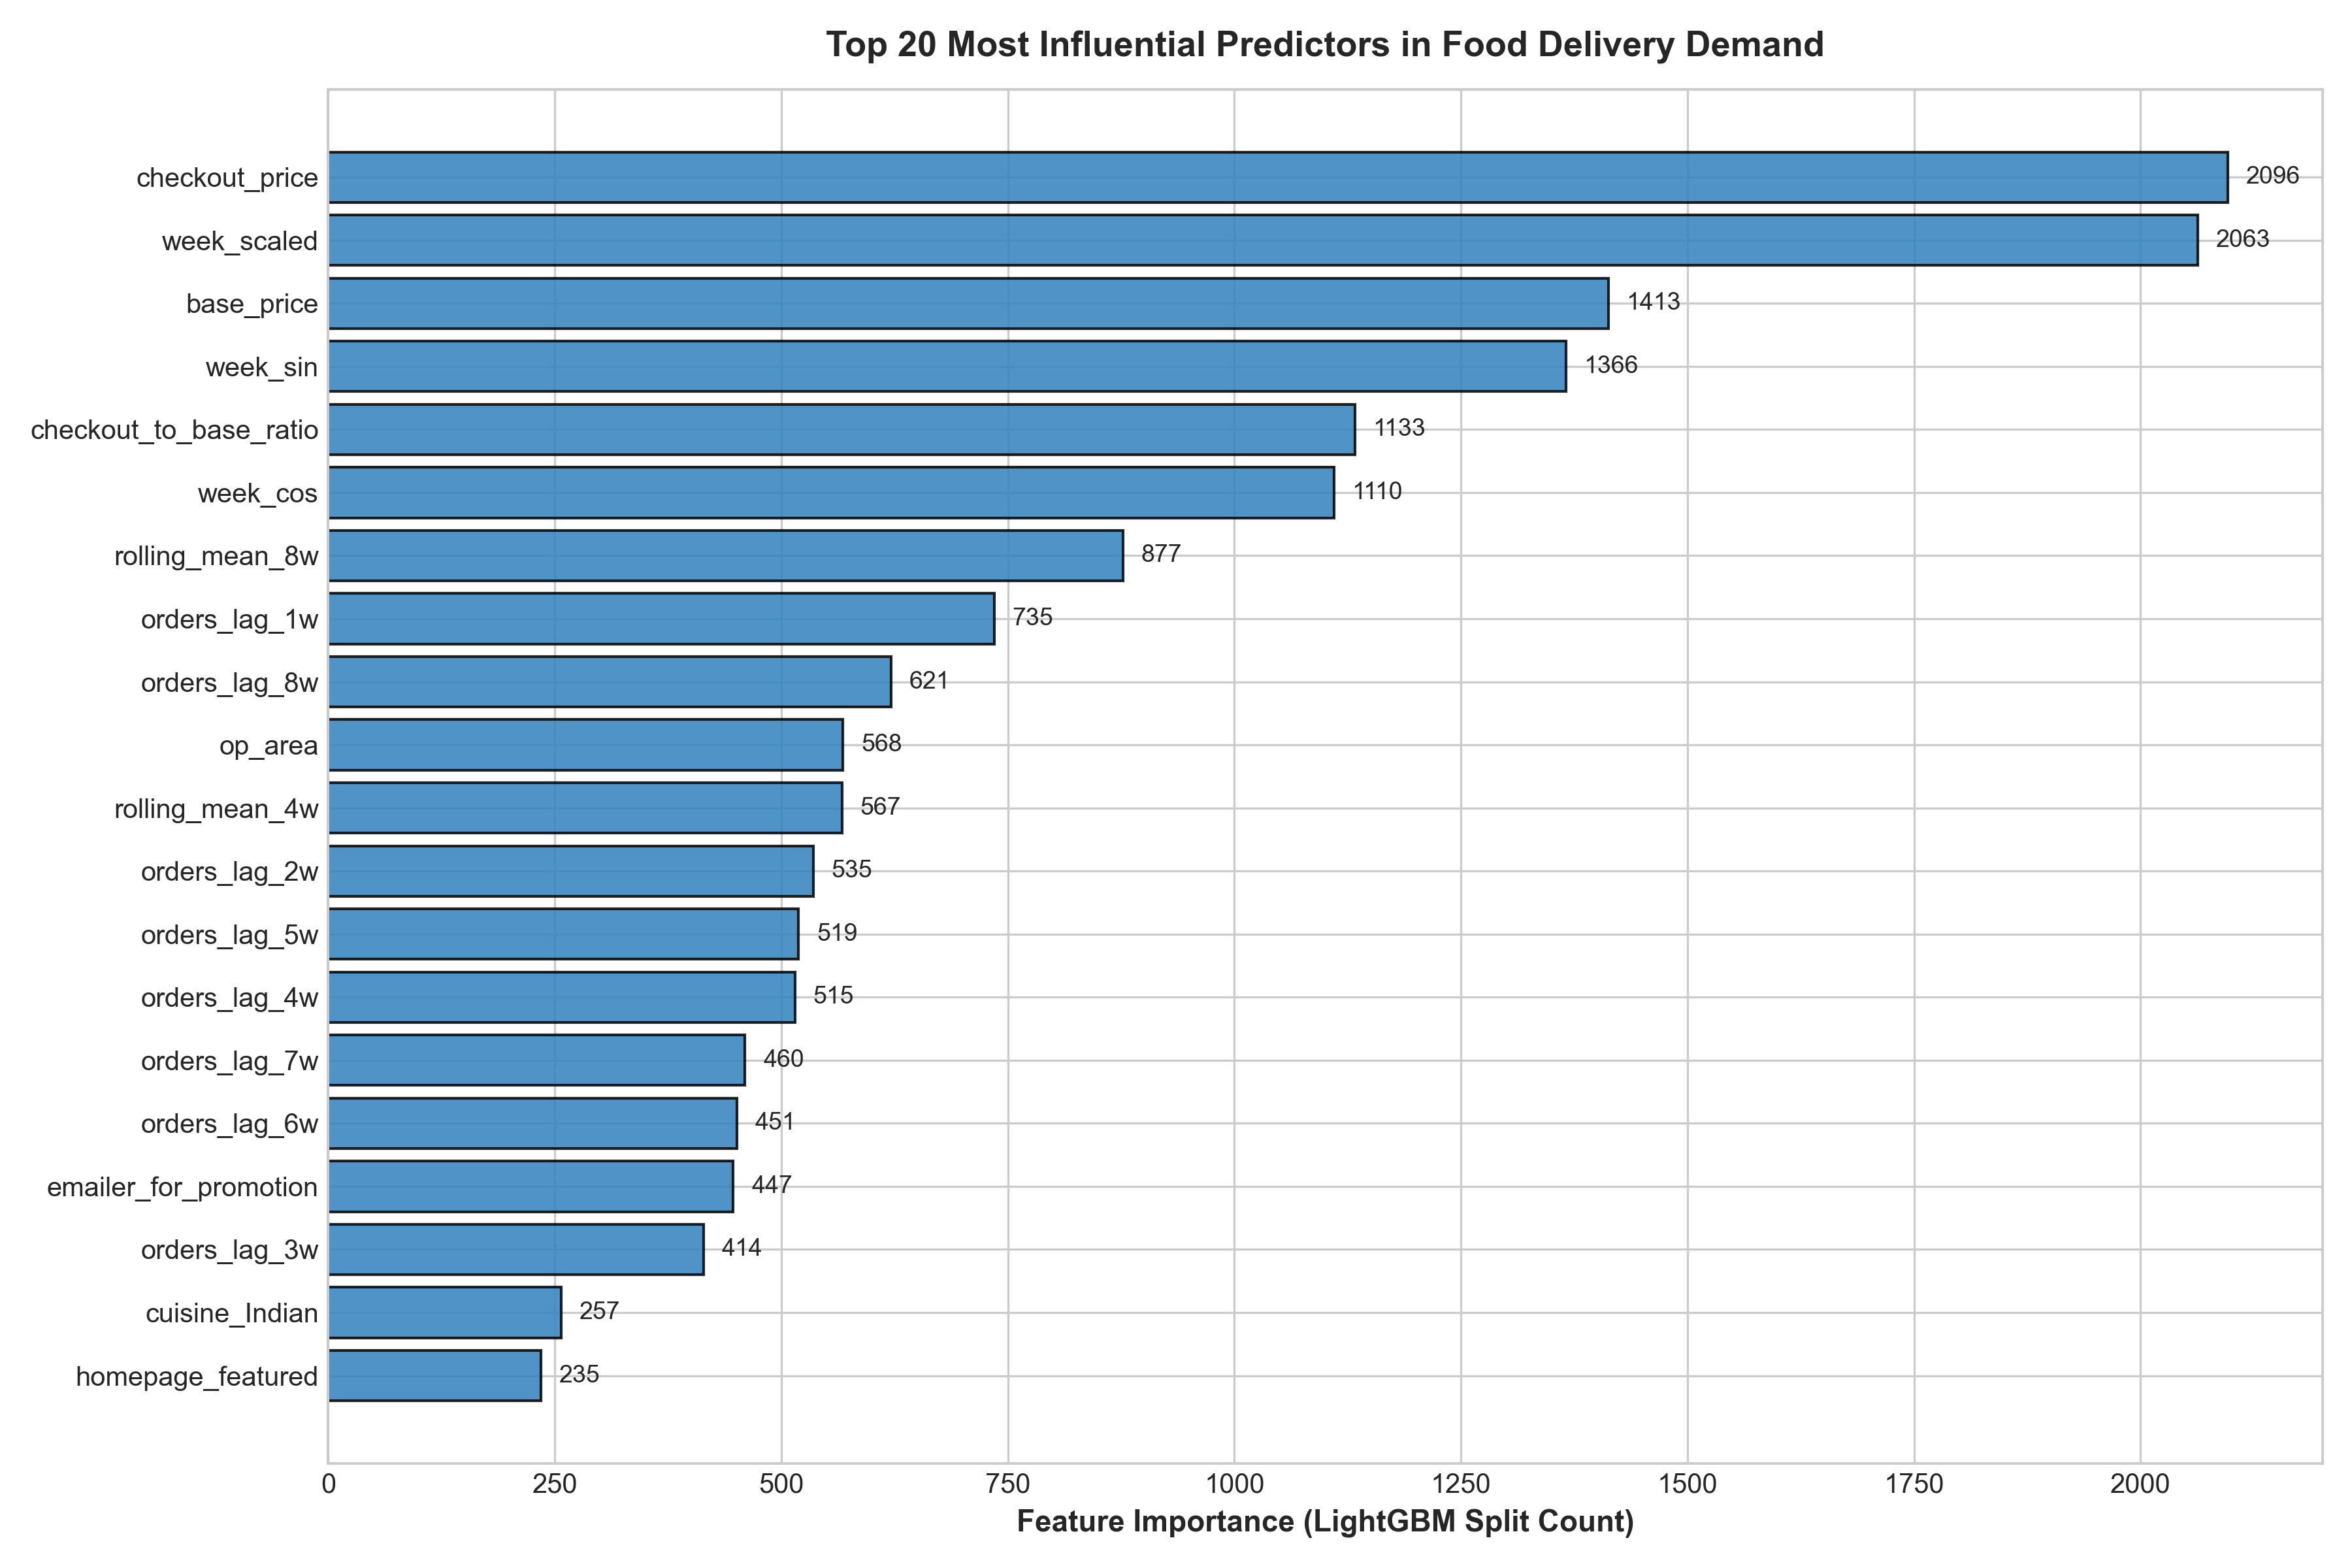

In [ ]:
feat_imp = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': lgbm_model.feature_importances_
}).sort_values('Importance', ascending=True).tail(20)

fig, ax = plt.subplots(figsize=(11, 7))
y_pos = np.arange(len(feat_imp))
bars = ax.barh(y_pos, feat_imp['Importance'], color='#3182bd', edgecolor='black', alpha=0.85)
ax.set_yticks(y_pos)
ax.set_yticklabels(feat_imp['Feature'], fontsize=10)
ax.set_xlabel('Feature Importance (LightGBM Split Count)', fontsize=11, fontweight='bold')
ax.set_title('Top 20 Most Influential Predictors in Food Delivery Demand', fontsize=13, fontweight='bold', pad=12)

for bar in bars:
    width = bar.get_width()
    ax.text(width + 20, bar.get_y() + bar.get_height()/2, f'{int(width)}', va='center', fontsize=9)

plt.tight_layout()
plt.show()

### 12. Model Serialization & Deployment Artifacts
We serialize the winning LightGBM pipeline artifact (`best_demand_lgbm.joblib`) containing model weights, pre-computed scalers, feature column mappings, and metadata. This enables direct integration into the Phase 4 Streamlit operational dashboard.

In [ ]:
os.makedirs('models', exist_ok=True)
model_artifacts = {
    'model': lgbm_model,
    'features': feature_cols,
    'scaler': scaler,
    'target_transform': 'log1p',
    'trained_weeks': (9, 120),
    'test_weeks': (121, 145),
    'metrics': res_lgbm
}
joblib.dump(model_artifacts, 'models/best_demand_lgbm.joblib')
print("Model pipeline successfully serialized to models/best_demand_lgbm.joblib")

Model pipeline successfully serialized to models/best_demand_lgbm.joblib
